# Step 4 - Random Forest

Train the forest that combines the centralities into one importance score. Target = PageRank of the original graph.
Two versions (decision D2): **with** PageRank among the inputs, and **without** it.
Logic is in `src/model.py`.

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('Final-Project'):
    !git clone https://github.com/ShaharBar99/Final-Project.git
    %cd Final-Project
    !pip install -q -r requirements.txt
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

## 1. Data

Scaled features from step 3 (scaler fitted on the original graph).

In [2]:
import json
import joblib
import pandas as pd
from src import config, model

x_all = pd.read_csv(config.PROCESSED_DIR / 'features_scaled.csv', index_col='paper_id')
y = x_all[model.TARGET]
variants = {
    'with_pagerank': model.FEATURES_WITH_PAGERANK,
    'without_pagerank': model.FEATURES_WITHOUT_PAGERANK,
}
x_all.shape

(19717, 5)

## 2. Sanity check on held-out papers (80 % train / 20 % test)

As a yardstick: how well does each single centrality alone follow PageRank (Spearman)?

In [3]:
check = {name: model.holdout_check(x_all[cols], y) for name, cols in variants.items()}
single = {c: x_all[c].corr(y, method='spearman') for c in model.FEATURES_WITHOUT_PAGERANK}
print(pd.DataFrame(check).T.round(3))
print()
print('single centrality vs PageRank (Spearman):')
print(pd.Series(single).round(3))

                     r2  spearman
with_pagerank     0.999     1.000
without_pagerank  0.747     0.797

single centrality vs PageRank (Spearman):
degree         0.288
betweenness    0.188
closeness      0.730
kcore          0.370
dtype: float64


**Reading the result.** With PageRank as an input the forest simply copies it (R^2 about 1) - it learned nothing about the network. Without it, the forest has to combine the other four measures, and it follows PageRank better than any one of them does. The second version is the interesting one for the stability question; the first stays in as the Phase A design.

## 3. Final models (trained on all papers, as in Phase A)

In [4]:
models, importance = {}, {}
for name, cols in variants.items():
    models[name] = model.train_model(x_all[cols], y)
    importance[name] = dict(zip(cols, models[name].feature_importances_.round(3)))
pd.DataFrame(importance)

,with_pagerank,without_pagerank
degree,0.002,0.436
betweenness,0.000,0.045
closeness,0.000,0.466
pagerank,0.998,NaN
kcore,0.000,0.053


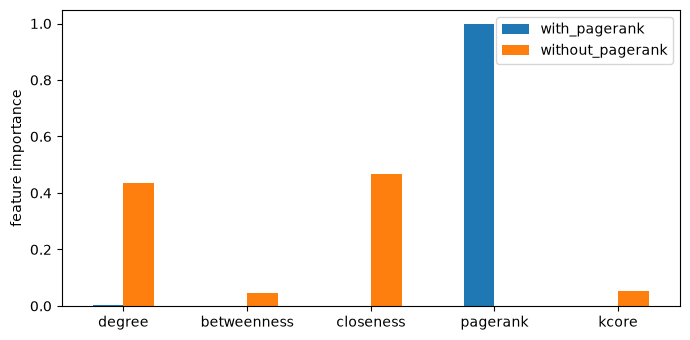

In [5]:
import matplotlib.pyplot as plt
pd.DataFrame(importance).plot.bar(figsize=(7, 3.5), rot=0)
plt.ylabel('feature importance'); plt.tight_layout(); plt.show()

## 4. Save

The models are 20-30 MB each, so they are **not** committed to GitHub (`data/processed/models/` is ignored). They are cheap to rebuild (a few seconds, fixed seed), so later notebooks just re-run this step if the file is missing. The metrics are small and are committed.

In [6]:
models_dir = config.PROCESSED_DIR / 'models'
models_dir.mkdir(exist_ok=True)
for name, m in models.items():
    joblib.dump(m, models_dir / f'rf_{name}.joblib')

report = {'holdout': check, 'single_centrality_spearman_vs_pagerank': single,
          'feature_importance': importance, 'forest_settings': model.FOREST_SETTINGS, 'seed': config.SEED}
with open(config.PROCESSED_DIR / 'model_report.json', 'w') as f:
    json.dump(report, f, indent=2, default=float)